## 1x2 그리드 윌드 

정책은 Left와 Right를 각각 확률 0.5로 선택하고, 할인율은 $\gamma=0.9$입니다.
**이 예제에는 종료 상태가 없습니다.** L2에 가더라도 계속 행동합니다.

| 현재 상태 | 행동 | 다음 상태 | 보상 |
| --- | --- | --- | ---: |
| L1 | Left | L1 | −1 |
| L1 | Right | L2 | +1 |
| L2 | Left | L1 | 0 |
| L2 | Right | L2 | −1 |

벨만 기대 방정식은 다음과 같습니다.

$$v_\pi(L1)=0.5[-1+0.9v_\pi(L1)]+0.5[1+0.9v_\pi(L2)]$$
$$v_\pi(L2)=0.5[0+0.9v_\pi(L1)]+0.5[-1+0.9v_\pi(L2)]$$

정리하면

$$\begin{bmatrix}0.55&-0.45\\-0.45&0.55\end{bmatrix}
\begin{bmatrix}v_\pi(L1)\\v_\pi(L2)\end{bmatrix}
=\begin{bmatrix}0\\-0.5\end{bmatrix}.$$

### 선형방정식 풀이



In [1]:
import numpy as np
A = np.array([[-0.55, 0.45], [0.45,-0.55]])
b = np.array([0, 0.5])
print(A, b)
print(np.linalg.inv(A) @ b)
print(np.linalg.solve(A,b))

[[-0.55  0.45]
 [ 0.45 -0.55]] [0.  0.5]
[-2.25 -2.75]
[-2.25 -2.75]


## 3×4 그리드 월드의 환경 모델

좌표는 `(행, 열)`이며 왼쪽 위가 `(0, 0)`입니다.

| 항목 | 규칙 |
| --- | --- |
| 행동 | 0: 위, 1: 아래, 2: 왼쪽, 3: 오른쪽 |
| 시작 | `(2, 0)` |
| 목표 | `(0, 3)`에 들어가면 +1을 받고 종료 |
| 벽 | `(1, 1)`에는 들어갈 수 없음 |
| 폭탄 | `(1, 3)`에 도착하면 −1, **종료하지 않음** |
| 경계·벽으로 이동 | 현재 위치에 머무름 |
| 보상 | **이동 결과의 칸**에 적힌 보상. 일반 칸에서는 0 |

폭탄 칸에서 경계 때문에 제자리에 머무는 경우에도 −1을 받습니다.


실습에 필요한 패키지는 `dezerogym`입니다. 

pip를 이용한 gridworld 설치

!pip install dezerogym

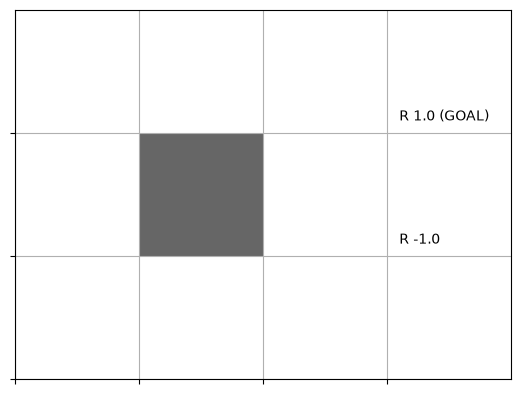

In [2]:
import numpy as np
from dezerogym.gridworld import GridWorld
env = GridWorld()
env.render_v()

## 상태 가치 테이블 시각화

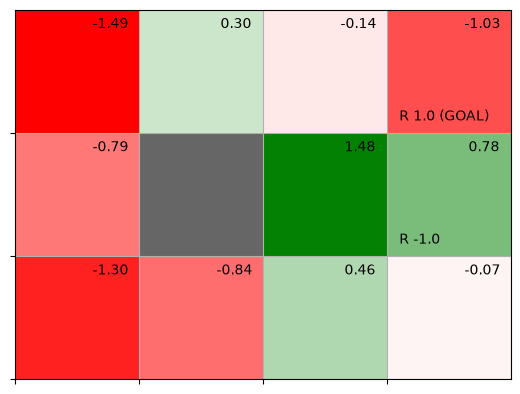

In [3]:
env = GridWorld()
V = {}

for state in env.states():
    V[state] = np.random.randn()
env.render_v(V)

## defaultdict 사용법


In [4]:
from dezerogym.gridworld import GridWorld

env = GridWorld()
V = {}
for state in env.states():
    V[state] = 0

state = (1,2)
print(V[state])
print(V)

0
{(0, 0): 0, (0, 1): 0, (0, 2): 0, (0, 3): 0, (1, 0): 0, (1, 1): 0, (1, 2): 0, (1, 3): 0, (2, 0): 0, (2, 1): 0, (2, 2): 0, (2, 3): 0}


In [5]:
from collections import defaultdict
env = GridWorld()
V = defaultdict(lambda: 0)
state = (1,2)
print(V.items())
print(V[state])
print(V.items())



dict_items([])
0
dict_items([((1, 2), 0)])


In [6]:
# V = defaultdict(lambda:0)
##1. V[(1,2)] # (1,2)가 없음
##2. lambda:0 # 호출 (init value)
##3. V[(1,2)] = 0 


In [7]:
pi = defaultdict(lambda: {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25})
state = (0, 1)
print(pi[state])

{0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}


In [8]:
import dezerogym.gridworld_render as render_helper

class GridWorld:
    """결정적 전이 모델을 제공하는 3×4 그리드 월드."""

    def __init__(self):
        self.action_space = [0, 1, 2, 3]
        self.action_meaning = {
            0: "UP",
            1: "DOWN",
            2: "LEFT",
            3: "RIGHT",
        }

        # 도착한 칸의 보상. None은 이동할 수 없는 벽이다.
        self.reward_map = np.array(
            [[0, 0, 0, 1.0],
             [0, None, 0, -1.0],
             [0, 0, 0, 0]]
        )
        self.goal_state = (0, 3)
        self.wall_state = (1, 1)
        self.start_state = (2, 0)
        self.agent_state = self.start_state

    @property
    def height(self):
        return len(self.reward_map)

    @property
    def width(self):
        return len(self.reward_map[0])

    @property
    def shape(self):
        return self.reward_map.shape

    def actions(self):
        return self.action_space

    def states(self):
        # 시각화를 위한 전체 좌표를 반환한다. DP 계산에서는 벽을 제외한다.
        for h in range(self.height):
            for w in range(self.width):
                yield (h, w)

    def next_state(self, state, action):
        """에이전트를 움직이지 않고 다음 상태만 계산한다 (환경 모델)."""
        if state == self.goal_state:
            return state  # 종료 후에는 목표에 머무른다.
        action_move_map = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        move = action_move_map[action]
        next_state = (state[0] + move[0], state[1] + move[1])
        ny, nx = next_state

        if nx < 0 or nx >= self.width or ny < 0 or ny >= self.height:
            next_state = state
        elif next_state == self.wall_state:
            next_state = state

        return next_state

    def reward(self, state, action, next_state):
        # 목표로 들어갈 때 +1, 이미 종료된 후에는 추가 보상이 없다.
        if state == self.goal_state:
            return 0.0
        return self.reward_map[next_state]

    def reset(self):
        self.agent_state = self.start_state
        return self.agent_state

    def step(self, action):
        """실제로 agent_state를 바꾸는 메서드. DP 평가에서는 사용하지 않는다."""
        state = self.agent_state
        next_state = self.next_state(state, action)
        reward = self.reward(state, action, next_state)
        done = (next_state == self.goal_state)

        self.agent_state = next_state
        return next_state, reward, done

    def render_v(self, v=None, policy=None, print_value=True):
        renderer = render_helper.Renderer(self.reward_map, self.goal_state,
                                          self.wall_state)
        renderer.render_v(v, policy, print_value)

### 한 번의 벨만 기대 갱신

이 환경은 행동이 주어지면 다음 상태가 하나로 정해지므로 다음과 같이 계산합니다.

$$V_{\mathrm{new}}(s)=\sum_a\pi(a\mid s)\left[r(s,a,s')+\gamma V(s')\right],\quad s'=f(s,a).$$

| 수식 | 코드 | 의미 |
| --- | --- | --- |
| $\pi(a\mid s)$ | `action_prob` | 행동 선택 확률 |
| $s'=f(s,a)$ | `env.next_state(state, action)` | 다음 상태 |
| $r(s,a,s')$ | `reward` | 즉시 보상 |
| $\gamma V(s')$ | `gamma * source[next_state]` | 할인된 미래 가치 |

`eval_onestep`의 한 번은 모든 유효 상태를 한 차례 순회(sweep)하는 것입니다. 행동 한 번이나 에피소드 한 번이 아닙니다.

init V=defaultdict(<function <lambda> at 0x109ceefc0>, {})
current V=defaultdict(<function <lambda> at 0x109ceefc0>, {})
state(0, 0), action=0, action_prob=0.25
state(0, 0), action=1, action_prob=0.25
state(0, 0), action=2, action_prob=0.25
state(0, 0), action=3, action_prob=0.25
current V=defaultdict(<function <lambda> at 0x109ceefc0>, {(0, 0): 0.0, (1, 0): 0, (0, 1): 0})
state(0, 1), action=0, action_prob=0.25
state(0, 1), action=1, action_prob=0.25
state(0, 1), action=2, action_prob=0.25
state(0, 1), action=3, action_prob=0.25
current V=defaultdict(<function <lambda> at 0x109ceefc0>, {(0, 0): 0.0, (1, 0): 0, (0, 1): 0.0, (0, 2): 0})
state(0, 2), action=0, action_prob=0.25
state(0, 2), action=1, action_prob=0.25
state(0, 2), action=2, action_prob=0.25
state(0, 2), action=3, action_prob=0.25
current V=defaultdict(<function <lambda> at 0x109ceefc0>, {(0, 0): 0.0, (1, 0): 0, (0, 1): 0.0, (0, 2): 0.25, (1, 2): 0, (0, 3): 0})
state(1, 0), action=0, action_prob=0.25
state(1, 0), action=1, 

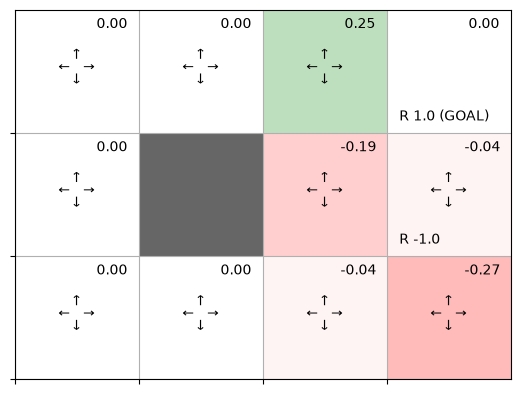

In [9]:
from collections import defaultdict
# from dezerogym.gridworld import GridWorld


def eval_onestep(pi, V, env, gamma=0.9):
    print(f"init V={V}")
    for state in env.states(): ## 현재 위치
        if state == env.goal_state:
            V[state] = 0
            continue

        action_probs = pi[state]
        new_V = 0
        print(f"current V={V}")

        for action, action_prob in action_probs.items():
            ## 0: "UP",
            ## 1: "DOWN",
            ## 2: "LEFT",
            ## 3: "RIGHT",
            print(f"state{state}, action={action}, action_prob={action_prob}")
            next_state = env.next_state(state, action)
            r = env.reward(state, action, next_state)
            new_V += action_prob * (r + gamma * V[next_state])
        V[state] = new_V
    return V


def policy_eval(pi, V, env, gamma, threshold=0.001):
    while True:
        old_V = V.copy()
        V = eval_onestep(pi, V, env, gamma)

        delta = 0
        for state in V.keys():
            t = abs(V[state] - old_V[state])
            if delta < t:
                delta = t

        if delta < threshold:
            break
        break
    return V


env = GridWorld()
gamma = 0.9

pi = defaultdict(lambda: {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25})
V = defaultdict(lambda: 0)

V = policy_eval(pi, V, env, gamma)
env.render_v(V, pi)


## 전이와 보상을 직접 확인하기

In [10]:
from collections import defaultdict
from dezerogym.gridworld import GridWorld

examples = [
    ((0, 0), 0),  # 위쪽 경계 → 제자리
    ((1, 0), 3),  # 벽 → 제자리
    ((0, 2), 3),  # 목표 → +1, 종료
    ((0, 3), 2),  # 종료 이후 → 제자리, 추가 보상 0
    ((0, 2), 1),  # 일반 칸으로 이동
    ((2, 3), 0),  # 폭탄 → -1, 계속 진행
    ((1, 3), 3),  # 폭탄에서 오른쪽 경계 → 제자리, -1
]
for state, action in examples:
    next_state = env.next_state(state, action)
    reward = env.reward(state, action, next_state)
    print(f"{state} / {env.action_meaning[action]:5s} → {next_state}, "
          f"보상={reward:+.0f}, 종료={next_state == env.goal_state}")
print("모델을 조회한 뒤 에이전트 위치:", env.agent_state)


(0, 0) / UP    → (0, 0), 보상=+0, 종료=False
(1, 0) / RIGHT → (1, 0), 보상=+0, 종료=False
(0, 2) / RIGHT → (0, 3), 보상=+1, 종료=True
(0, 3) / LEFT  → (0, 3), 보상=+0, 종료=True
(0, 2) / DOWN  → (1, 2), 보상=+0, 종료=False
(2, 3) / UP    → (1, 3), 보상=-1, 종료=False
(1, 3) / RIGHT → (1, 3), 보상=-1, 종료=False
모델을 조회한 뒤 에이전트 위치: (2, 0)


## 변화가 충분히 작아질 때까지 반복하기

$$\Delta_k=\max_s|V_{k+1}(s)-V_k(s)|$$


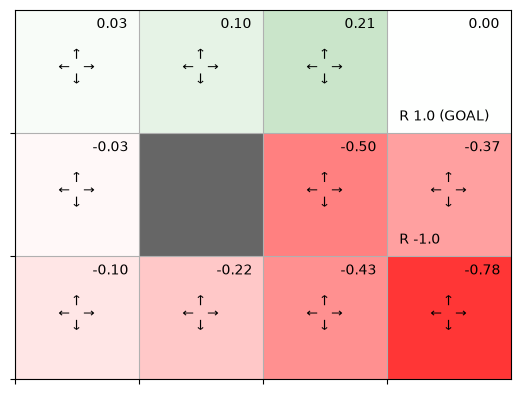

In [14]:

from collections import defaultdict


def eval_onestep(pi, V, env, gamma=0.9):
    for state in env.states():
        if state == env.goal_state:
            V[state] = 0
            continue

        action_probs = pi[state]
        new_V = 0
        for action, action_prob in action_probs.items():
            next_state = env.next_state(state, action)
            r = env.reward(state, action, next_state)
            new_V += action_prob * (r + gamma * V[next_state])
        V[state] = new_V
    return V


def policy_eval(pi, V, env, gamma, threshold=0.001):
    while True:
        old_V = V.copy()
        V = eval_onestep(pi, V, env, gamma)

        delta = 0
        for state in V.keys():
            t = abs(V[state] - old_V[state])
            if delta < t:
                delta = t

        if delta < threshold:
            break
    return V


env = GridWorld()
gamma = 0.9

pi = defaultdict(lambda: {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25})
V = defaultdict(lambda: 0)

V = policy_eval(pi, V, env, gamma)
env.render_v(V, pi)